# PMR3508-2026-24: Classificação da base Adult com kNN

**Autor:** Gabriel da Silva Simões - NºUSP 13875032

## Objetivo

Prever se a renda anual de uma pessoa é maior que 50 mil dólares (`>50K`) ou não (`<=50K`) a partir de características demográficas e profissionais, usando o classificador k-vizinhos mais próximos (kNN). A base é a *Adult* do repositório UCI (censo dos EUA de 1994), com 32.561 registros de treino e 16.281 de teste (`adult.data` e `adult.test`). A abordagem final de kNN, com o pré-processamento selecionado e `k=51`, também é utilizada na submissão ao Kaggle (`test_data.csv`). Para a submissão, o pipeline é ajustado com todos os registros de treino e incorpora imputação dos valores categóricos ausentes.

## Estrutura do notebook

1. **Carregamento dos dados:** leitura de `adult.data`, `adult.test` e `test_data.csv`, com os tratamentos de formato necessários.
2. **Análise exploratória:** distribuição do alvo, valores ausentes, variáveis numéricas e categóricas, relações com a renda e possíveis redundâncias.
3. **Modelo base:** kNN com pré-processamento em pipeline, escolha de `k` por validação cruzada, avaliação no holdout, matriz de confusão e curva de `k`.
4. **Ablações:** efeito de remover ou transformar variáveis, guiado pela análise exploratória; inclui o modelo final (seção 3.7), com nova busca de `k` e avaliação única no holdout.
5. **Submissão para o Kaggle:** pipeline treinado com todos os dados e imputação de ausentes.
6. **Conclusão:** resultados, limitações e considerações éticas.

## Resultados em resumo

| Modelo | Acurácia (holdout) | Recall de `>50K` | Score no Kaggle |
|---|---:|---:|---:|
| Base (`k=41`) | 0,8390 | 0,607 | 0,84275 |
| Final (`k=51`) | 0,8446 | 0,646 | 0,84815 |

In [1]:
import pandas as pd
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score
from sklearn.impute import SimpleImputer
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.preprocessing import FunctionTransformer

In [2]:
import os

def achar_arquivo(*candidatos):
    """Devolve o primeiro caminho que existe: pasta local ou pastas do Kaggle."""
    for caminho in candidatos:
        if os.path.exists(caminho):
            return caminho
    raise FileNotFoundError(f"Nenhum destes caminhos existe: {candidatos}")

CAMINHO_ADULT_DATA = achar_arquivo(
    "adult.data",
    "/kaggle/input/datasets/gabrieldasilvasimoes/adult-ucl/adult.data",
)
CAMINHO_ADULT_TEST = achar_arquivo(
    "adult.test",
    "/kaggle/input/datasets/gabrieldasilvasimoes/adult-ucl/adult.test",
)
CAMINHO_KAGGLE = achar_arquivo(
    "test_data.csv",
    "/kaggle/input/competitions/adult-pmr3508/test_data.csv",
)
print(CAMINHO_ADULT_DATA, CAMINHO_ADULT_TEST, CAMINHO_KAGGLE, sep="\n")


adult.data
adult.test
test_data.csv


## 1. Carregamento dos dados

Três arquivos são usados: `adult.data` (treino, 32.561 linhas), `adult.test` (teste, 16.281 linhas) e `test_data.csv` (teste do Kaggle, sem rótulos). Decisões de leitura:

- **Separador:** os arquivos usam vírgula seguida de espaço, então `sep=r'\s*,\s*'` (expressão regular) remove os espaços ao ler, e `engine='python'` é necessário para aceitar essa expressão.
- **Ausentes:** a base marca valores desconhecidos com `?`; `na_values="?"` converte esses valores em `NaN` já na leitura.
- **`adult.test`:** a primeira linha é um comentário, por isso `skiprows=1`; e os rótulos do teste terminam com ponto (`<=50K.`), diferente do treino, então o ponto é removido com `str.rstrip(".")` para os rótulos coincidirem com os de treino.
- **Kaggle:** `test_data.csv` não tem a coluna `Target` e traz uma coluna `Id`, guardada à parte para montar a submissão.

In [3]:
adult_data = pd.read_csv(CAMINHO_ADULT_DATA,
        names=[
        "Age", "Workclass", "fnlwgt", "Education", "Education-Num", "Marital Status",
        "Occupation", "Relationship", "Race", "Sex", "Capital Gain", "Capital Loss",
        "Hours per week", "Country", "Target"],
        sep=r'\s*,\s*',
        engine='python',
        na_values="?")

In [4]:
adult_data.shape


(32561, 15)

In [5]:
adult_data.head()

,Age,Workclass,fnlwgt,Education,Education-Num,Marital Status,Occupation,Relationship,Race,Sex,Capital Gain,Capital Loss,Hours per week,Country,Target
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [6]:
adult_test = pd.read_csv(CAMINHO_ADULT_TEST,skiprows=1,
        names=[
        "Age", "Workclass", "fnlwgt", "Education", "Education-Num", "Marital Status",
        "Occupation", "Relationship", "Race", "Sex", "Capital Gain", "Capital Loss",
        "Hours per week", "Country", "Target"],
        sep=r'\s*,\s*',
        engine='python',
        na_values="?")

In [7]:
adult_test.shape

(16281, 15)

In [8]:
adult_test.head()

,Age,Workclass,fnlwgt,Education,Education-Num,Marital Status,Occupation,Relationship,Race,Sex,Capital Gain,Capital Loss,Hours per week,Country,Target
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K.
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K.
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K.
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K.
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States,<=50K.


In [9]:
adult_test["Target"].value_counts()

Target
<=50K.    12435
>50K.      3846
Name: count, dtype: int64

In [10]:
adult_test["Target"] = adult_test["Target"].str.rstrip(".")

In [11]:
adult_test["Target"].value_counts()

Target
<=50K    12435
>50K      3846
Name: count, dtype: int64

In [12]:
kaggle_data = pd.read_csv(CAMINHO_KAGGLE, na_values="?")
kaggle_data.shape

(16280, 15)

In [13]:
kaggle_data.isna().sum()


Id                  0
age                 0
workclass         963
fnlwgt              0
education           0
education.num       0
marital.status      0
occupation        966
relationship        0
race                0
sex                 0
capital.gain        0
capital.loss        0
hours.per.week      0
native.country    274
dtype: int64

In [14]:
kaggle_data.head()

,Id,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country
0,0,25,Private,120596,Bachelors,13,Never-married,Prof-specialty,Not-in-family,White,Male,0,0,44,United-States
1,1,64,State-gov,152537,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,45,United-States
2,2,31,Private,100135,Masters,14,Divorced,Exec-managerial,Not-in-family,White,Female,0,0,40,United-States
3,3,45,Private,189123,HS-grad,9,Never-married,Machine-op-inspct,Own-child,White,Male,0,0,40,United-States
4,4,64,Self-emp-inc,487751,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,50,United-States


In [15]:
colunas_numericas = ["Age", "fnlwgt", "Education-Num", "Capital Gain", "Capital Loss", "Hours per week"]
colunas_categoricas = ["Workclass", "Education", "Marital Status", "Occupation", "Relationship", "Race", "Sex", "Country"]

In [16]:
len(colunas_numericas)

6

In [17]:
len(colunas_categoricas)

8

## 2. Análise exploratória

Nesta seção exploramos os dados antes de modelar, para que as decisões de pré-processamento e de modelagem sejam justificadas pelo que observamos.

### 2.1 Distribuição do Target

Verificamos se as classes `<=50K` e `>50K` estão equilibradas, o que afeta a forma de interpretar a acurácia do classificador.

Target
<=50K    0.75919
>50K     0.24081
Name: proportion, dtype: float64


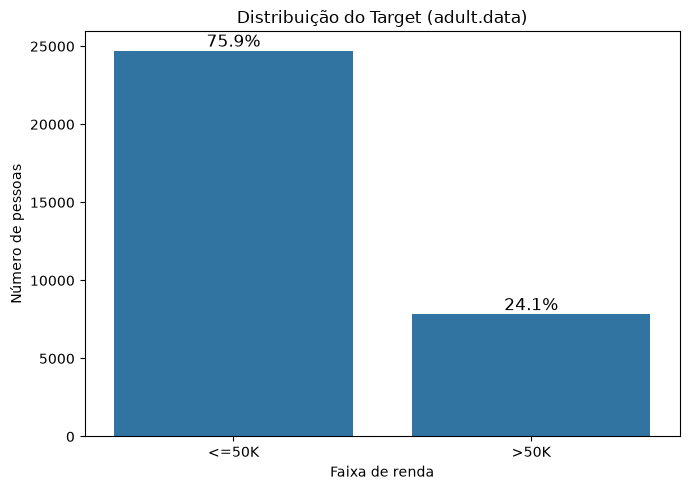

In [18]:

proporcoes = adult_data["Target"].value_counts(normalize=True)
print(proporcoes)

fig, ax = plt.subplots(figsize=(7, 5))
sns.countplot(data=adult_data, x="Target", order=["<=50K", ">50K"], ax=ax)

# porcentagem sobre cada barra
total = len(adult_data)
for barra in ax.patches:
    altura = barra.get_height()
    ax.annotate(f"{altura / total:.1%}",
                (barra.get_x() + barra.get_width() / 2, altura),
                ha="center", va="bottom", fontsize=12)

ax.set_title("Distribuição do Target (adult.data)")
ax.set_xlabel("Faixa de renda")
ax.set_ylabel("Número de pessoas")
plt.tight_layout()
plt.show()

**Conclusão.** As classes são desbalanceadas: cerca de 75,9% das pessoas ganham `<=50K` e apenas 24,1% ganham `>50K`. Isso significa que um modelo que prevesse sempre `<=50K` já acertaria cerca de 76%, então a acurácia do kNN deve ser lida contra essa linha de base. Além disso, a acurácia sozinha pode esconder um desempenho pior na classe minoritária (`>50K`), por isso mais adiante vamos analisar também a matriz de confusão e a revocação dessa classe.

### 2.2 Valores ausentes

Verificamos quais colunas têm valores faltantes e quantos, porque isso decide como tratar os dados no treino e na submissão.

In [19]:
adult_data.isna().sum()

Age                  0
Workclass         1836
fnlwgt               0
Education            0
Education-Num        0
Marital Status       0
Occupation        1843
Relationship         0
Race                 0
Sex                  0
Capital Gain         0
Capital Loss         0
Hours per week       0
Country            583
Target               0
dtype: int64

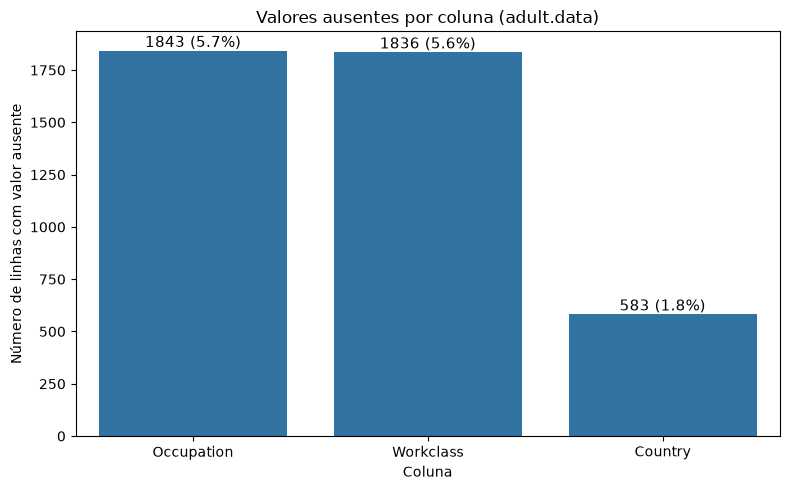

Linhas com algum valor ausente: 2399 de 32561


In [20]:
ausentes = adult_data.isna().sum()
ausentes = ausentes[ausentes > 0].sort_values(ascending=False)
percentual = ausentes / len(adult_data)

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=ausentes.index, y=ausentes.values, ax=ax)

# contagem e porcentagem sobre cada barra
for barra, p in zip(ax.patches, percentual.values):
    altura = barra.get_height()
    ax.annotate(f"{int(altura)} ({p:.1%})",
                (barra.get_x() + barra.get_width() / 2, altura),
                ha="center", va="bottom", fontsize=11)

ax.set_title("Valores ausentes por coluna (adult.data)")
ax.set_xlabel("Coluna")
ax.set_ylabel("Número de linhas com valor ausente")
plt.tight_layout()
plt.show()

print(f"Linhas com algum valor ausente: {adult_data.isna().any(axis=1).sum()} de {len(adult_data)}")

**Conclusão.** Apenas três colunas categóricas têm valores ausentes: `Workclass` (1836, cerca de 5,6%), `Occupation` (1843, cerca de 5,7%) e `Country` (583, cerca de 1,8%). Nenhuma coluna numérica tem ausentes. Descartar as linhas incompletas elimina 2399 registros (cerca de 7% da base) e deixa 30162 no treino, o que é aceitável para a validação cruzada e para o holdout. No `test_data.csv` do Kaggle, porém, também há ausentes (963, 966 e 274), e como todas as linhas precisam receber uma previsão, não é possível descartá-las; por isso o modelo usado na submissão trata os ausentes por imputação pela moda.

### 2.3 Variáveis numéricas

Comparamos a distribuição de cada variável numérica entre as duas classes de renda, para identificar quais ajudam a separá-las e quais pouco informam.

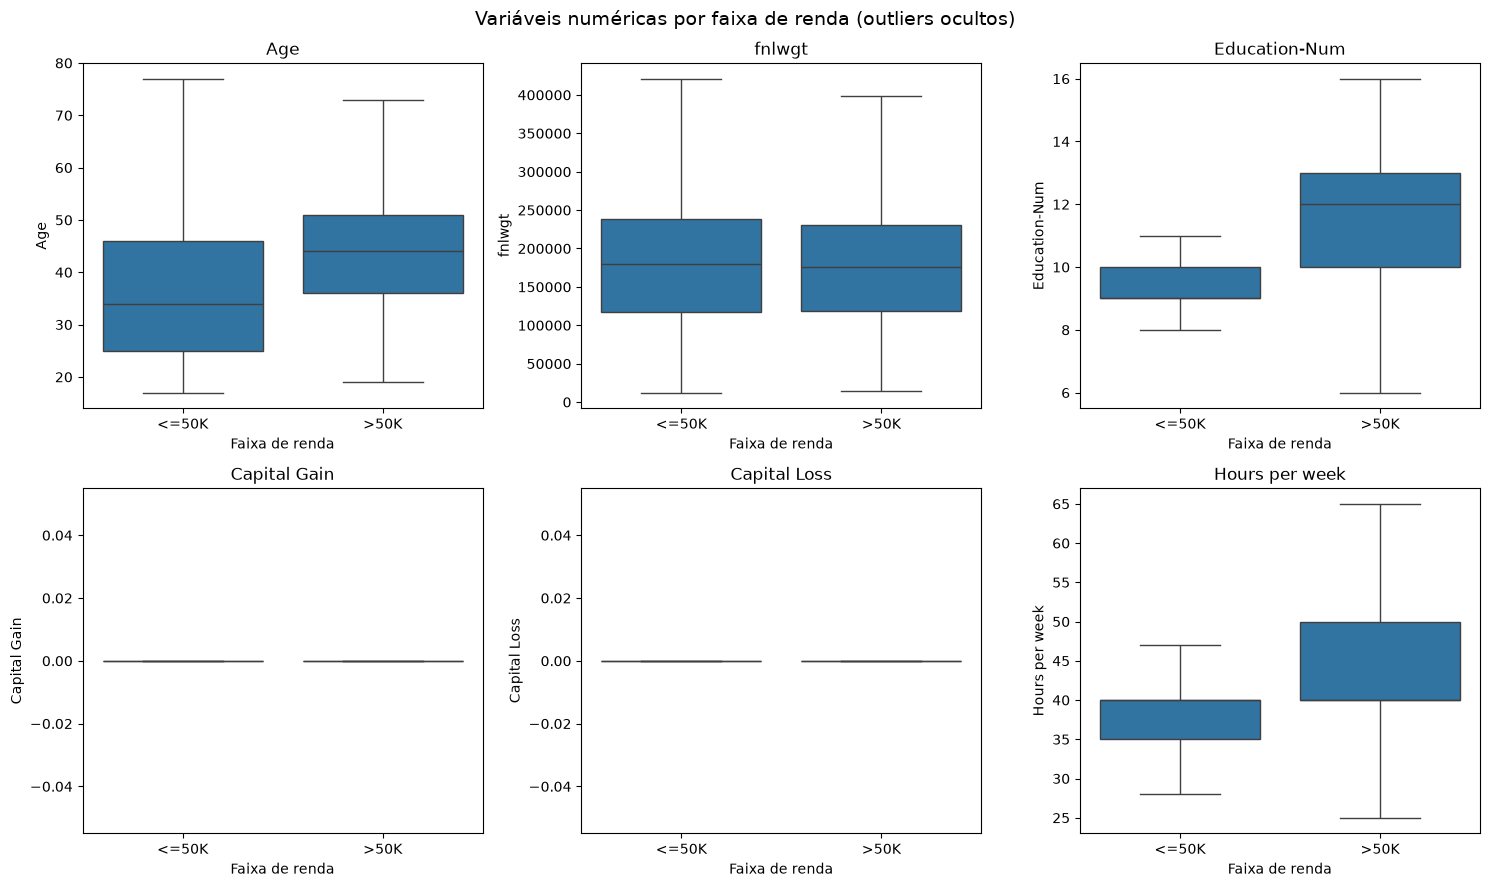

In [21]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, coluna in zip(axes.ravel(), colunas_numericas):
    sns.boxplot(data=adult_data, x="Target", y=coluna, order=["<=50K", ">50K"],
                showfliers=False, ax=ax)
    ax.set_title(coluna)
    ax.set_xlabel("Faixa de renda")
fig.suptitle("Variáveis numéricas por faixa de renda (outliers ocultos)", fontsize=14)
plt.tight_layout()
plt.show()

In [22]:
print("Mediana por classe:")
print(adult_data.groupby("Target")[colunas_numericas].median())
print()
print("Proporção com valor maior que zero, por classe:")
print(adult_data.groupby("Target")[["Capital Gain", "Capital Loss"]].agg(lambda s: (s > 0).mean()))

Mediana por classe:
         Age    fnlwgt  Education-Num  Capital Gain  Capital Loss  \
Target                                                              
<=50K   34.0  179465.0            9.0           0.0           0.0   
>50K    44.0  176101.0           12.0           0.0           0.0   

        Hours per week  
Target                  
<=50K             40.0  
>50K              40.0  

Proporção com valor maior que zero, por classe:
        Capital Gain  Capital Loss
Target                            
<=50K       0.041869      0.030178
>50K        0.213876      0.098584


**Conclusão.** `Age` e `Education-Num` diferenciam as classes nas distribuições observadas: quem ganha `>50K` tem mediana de 44 anos contra 34, e 12 anos de estudo contra 9. `fnlwgt` tem medianas semelhantes nas duas classes (cerca de 179 mil contra 176 mil), sugerindo capacidade discriminativa limitada nessa comparação; por isso, é um candidato a ablação. `Hours per week` tem mediana 40 nas duas classes, mas a distribuição da classe `>50K` se estende para valores mais altos. `Capital Gain` e `Capital Loss` são zero para a maioria das pessoas, de modo que a mediana é 0 nas duas classes e o boxplot é pouco informativo. A tabela de proporções mostra que 21,4% de quem ganha `>50K` tem ganho de capital, contra 4,2% na outra classe (para perda de capital, 9,9% contra 3,0%). Como essas variáveis são muito assimétricas, vale testar uma transformação logarítmica nas ablações.

### 2.3.1 Distribuição de cada variável numérica

Os boxplots resumem a distribuição em poucos números. Aqui olhamos o formato completo de cada variável, para ver assimetria e concentração de valores.

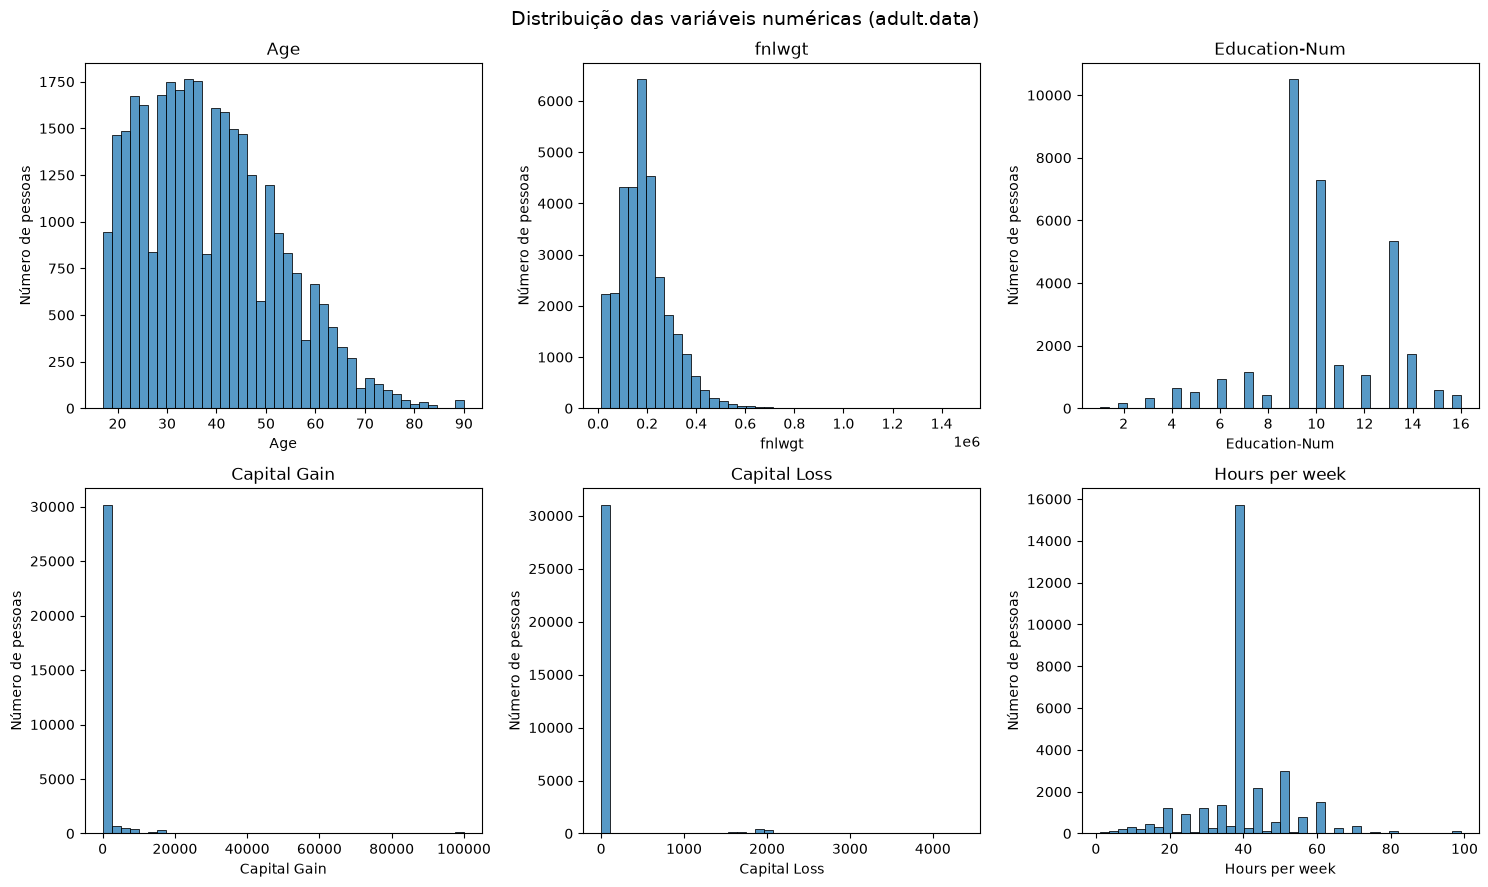

In [23]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, coluna in zip(axes.ravel(), colunas_numericas):
    sns.histplot(data=adult_data, x=coluna, bins=40, ax=ax)
    ax.set_title(coluna)
    ax.set_xlabel(coluna)
    ax.set_ylabel("Número de pessoas")
fig.suptitle("Distribuição das variáveis numéricas (adult.data)", fontsize=14)
plt.tight_layout()
plt.show()

In [24]:
print("Assimetria (skew) de cada variável numérica:")
print(adult_data[colunas_numericas].skew().round(2))
print()
print("Proporção de zeros:")
print((adult_data[["Capital Gain", "Capital Loss"]] == 0).mean().round(3))

Assimetria (skew) de cada variável numérica:
Age                0.56
fnlwgt             1.45
Education-Num     -0.31
Capital Gain      11.95
Capital Loss       4.59
Hours per week     0.23
dtype: float64

Proporção de zeros:
Capital Gain    0.917
Capital Loss    0.953
dtype: float64


In [25]:
print((adult_data["Capital Gain"] == 99999).sum())

159


**Conclusão.** As variáveis têm formatos diferentes, o que importa para o kNN, que calcula distâncias. `Capital Gain` (assimetria 11,95) e `Capital Loss` (4,59) são extremamente assimétricas: 91,7% e 95,3% das pessoas têm valor zero, enquanto poucos valores altos estendem a distribuição. Em `Capital Gain` há um pico em 99.999, com 159 registros exatamente nesse valor. Esse padrão pode refletir um limite ou uma particularidade de codificação da variável; a análise exploratória, isoladamente, não permite determinar a causa. Depois da padronização, valores extremos podem influenciar as distâncias, por isso a transformação logarítmica é uma ablação promissora. `fnlwgt` também tem cauda longa à direita (assimetria 1,45), mas as medianas semelhantes entre as classes sugerem capacidade discriminativa limitada nessa comparação. `Hours per week` concentra a maior parte dos registros em 40 horas, com assimetria baixa (0,23). `Age` é moderadamente assimétrica (0,56), concentrada entre 20 e 50 anos, e o pico em 90 anos pode refletir truncamento da variável. `Education-Num` se concentra em 9 (`HS-grad`), 10 (`Some-college`) e 13 (`Bachelors`).

### 2.4 Variáveis categóricas

Comparamos a proporção de pessoas com renda `>50K` dentro de cada categoria, para ver quais categorias concentram renda alta.

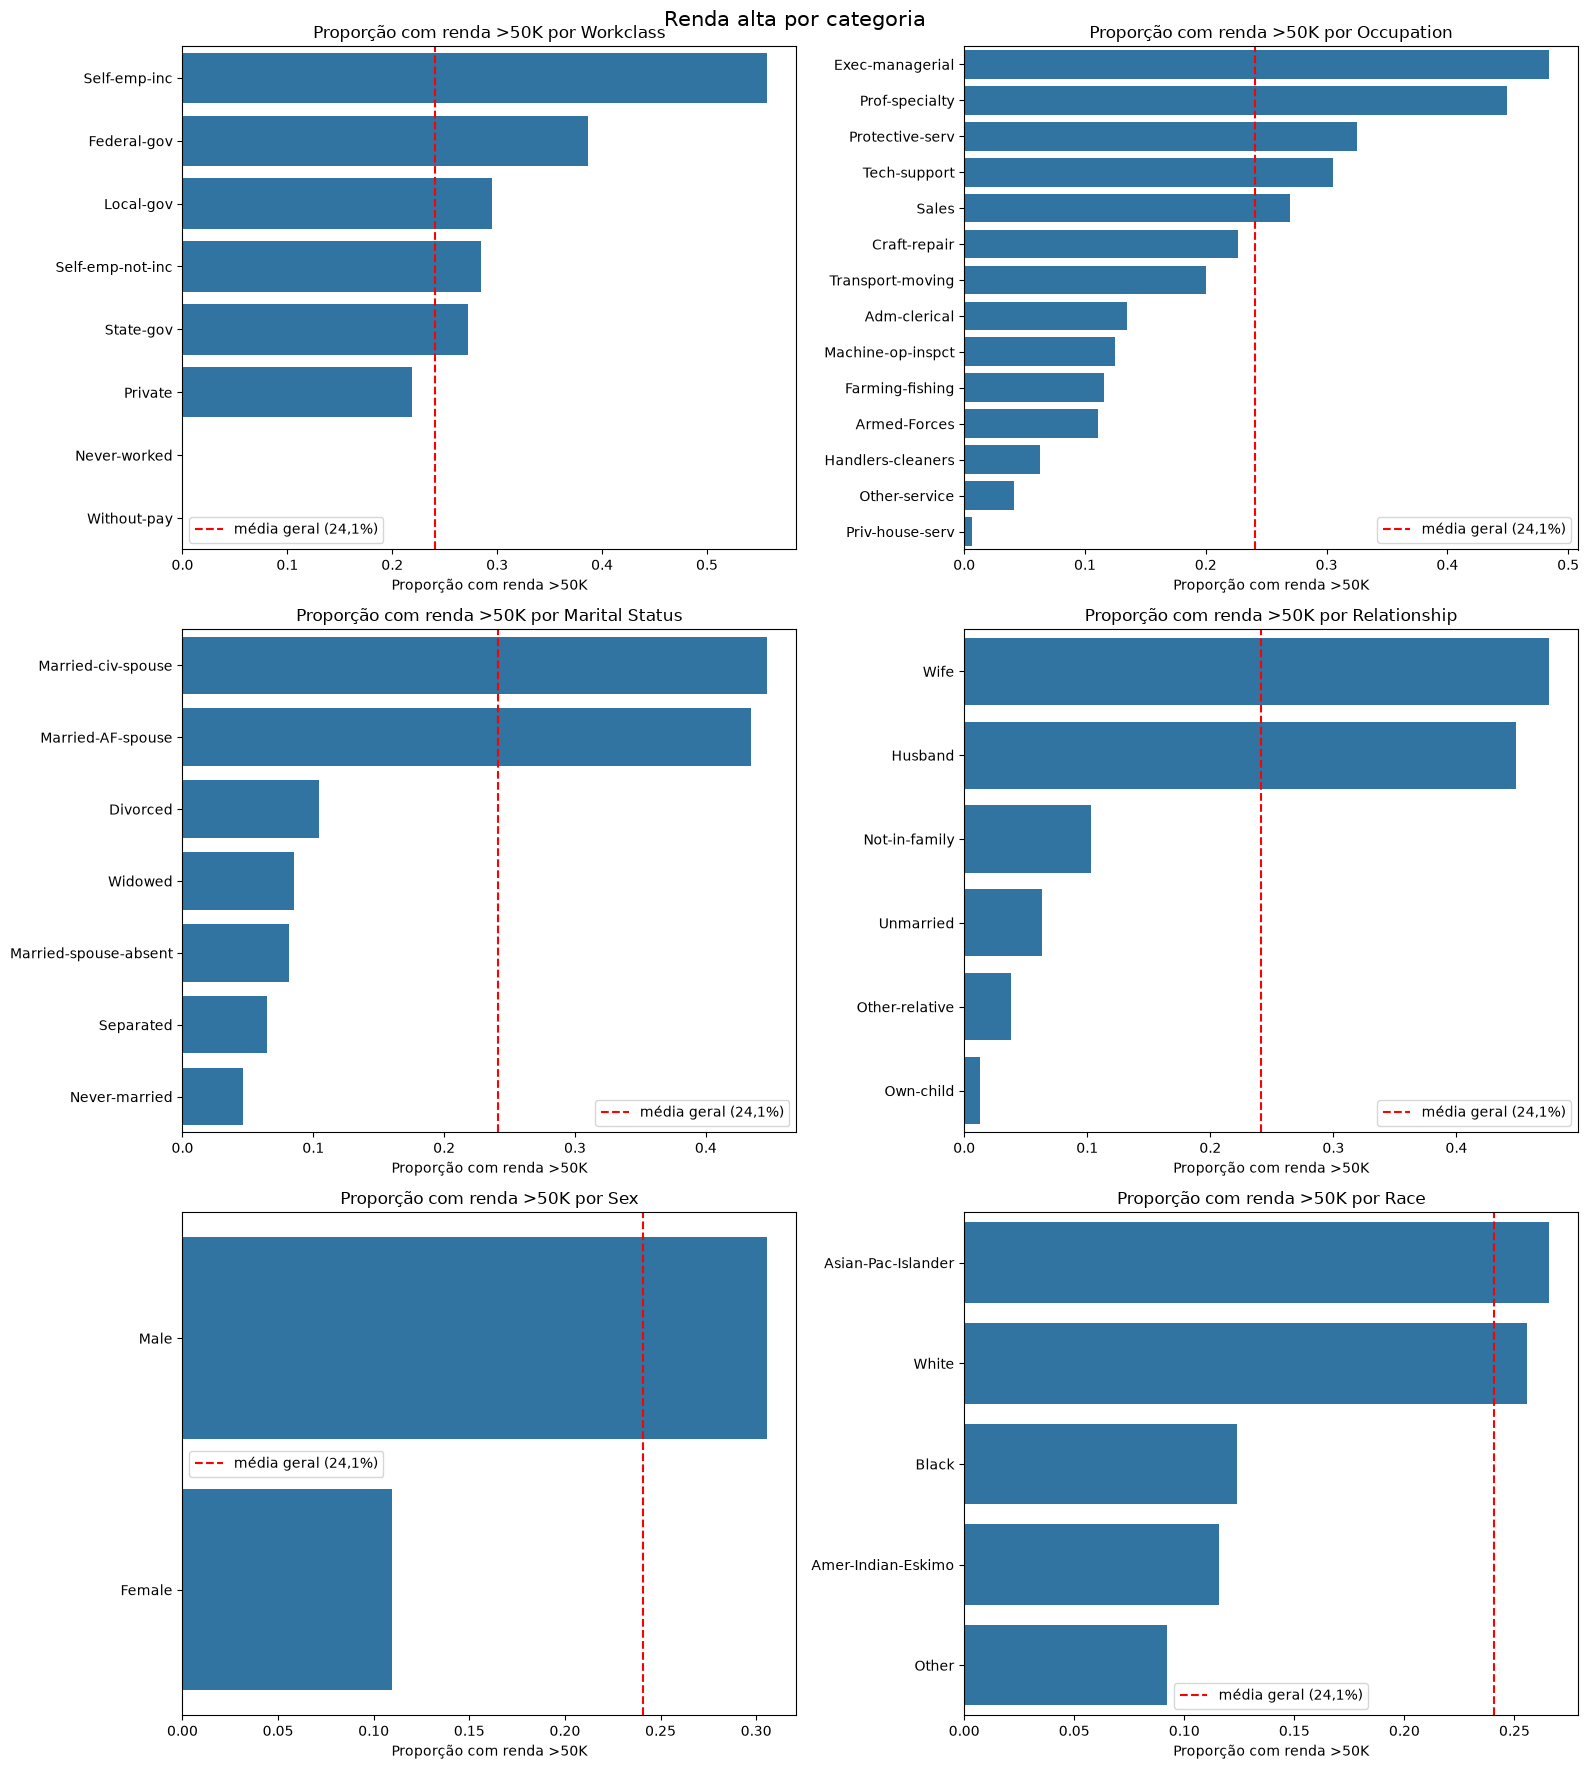

In [26]:
cols_cat = ["Workclass", "Occupation", "Marital Status", "Relationship", "Sex", "Race"]

fig, axes = plt.subplots(3, 2, figsize=(16, 18))
for ax, coluna in zip(axes.ravel(), cols_cat):
    taxa = (adult_data.assign(alta=adult_data["Target"] == ">50K")
            .groupby(coluna)["alta"].mean().sort_values(ascending=False))
    sns.barplot(x=taxa.values, y=taxa.index, ax=ax)
    ax.axvline(0.2408, color="red", linestyle="--", label="média geral (24,1%)")
    ax.set_title(f"Proporção com renda >50K por {coluna}")
    ax.set_xlabel("Proporção com renda >50K")
    ax.set_ylabel("")
    ax.legend()
fig.suptitle("Renda alta por categoria", fontsize=15)
plt.tight_layout()
plt.show()

In [27]:
for c in ["Workclass", "Occupation", "Sex", "Race"]:
    print((adult_data.assign(alta=adult_data["Target"] == ">50K").groupby(c)["alta"].agg(["mean", "count"])).round(3), "\n")

                   mean  count
Workclass                     
Federal-gov       0.386    960
Local-gov         0.295   2093
Never-worked      0.000      7
Private           0.219  22696
Self-emp-inc      0.557   1116
Self-emp-not-inc  0.285   2541
State-gov         0.272   1298
Without-pay       0.000     14 

                    mean  count
Occupation                     
Adm-clerical       0.134   3770
Armed-Forces       0.111      9
Craft-repair       0.227   4099
Exec-managerial    0.484   4066
Farming-fishing    0.116    994
Handlers-cleaners  0.063   1370
Machine-op-inspct  0.125   2002
Other-service      0.042   3295
Priv-house-serv    0.007    149
Prof-specialty     0.449   4140
Protective-serv    0.325    649
Sales              0.269   3650
Tech-support       0.305    928
Transport-moving   0.200   1597 

         mean  count
Sex                 
Female  0.109  10771
Male    0.306  21790 

                     mean  count
Race                            
Amer-Indian-Eskimo  0.

**Conclusão.** As categorias separam bem as classes. Em `Occupation`, cargos como `Exec-managerial` e `Prof-specialty` têm cerca de 45% a 48% de renda alta, contra 6,3% ou menos em `Handlers-cleaners`, `Other-service` (4,2%) e `Priv-house-serv` (0,7%). Em `Workclass`, `Self-emp-inc` e `Federal-gov` ficam bem acima da média de 24,1%, e `Private` fica abaixo; `Never-worked` e `Without-pay` aparecem com 0%, mas têm pouquíssimos registros, então não dá para generalizar. `Marital Status` e `Relationship` carregam praticamente a mesma informação: pessoas casadas (`Married-civ-spouse`, `Husband`, `Wife`) têm cerca de 45% de renda alta, enquanto `Never-married` e `Own-child` ficam perto de 5% e 1%. Essa redundância sugere testar, nas ablações, manter só uma das duas. `Sex` e `Race` também mostram diferenças marcantes (homens ~30% contra mulheres ~11%; brancos e asiáticos acima de negros e indígenas). Essas diferenças refletem desigualdades presentes nos dados de 1994, e não uma relação causal. Um modelo que use essas variáveis pode reproduzir esse viés, e isso é uma questão ética a ser discutida na conclusão final.

### 2.4.1 Frequência das categorias

As taxas de renda alta só são confiáveis se o grupo tem pessoas suficientes. Aqui vemos quantas pessoas há em cada categoria.

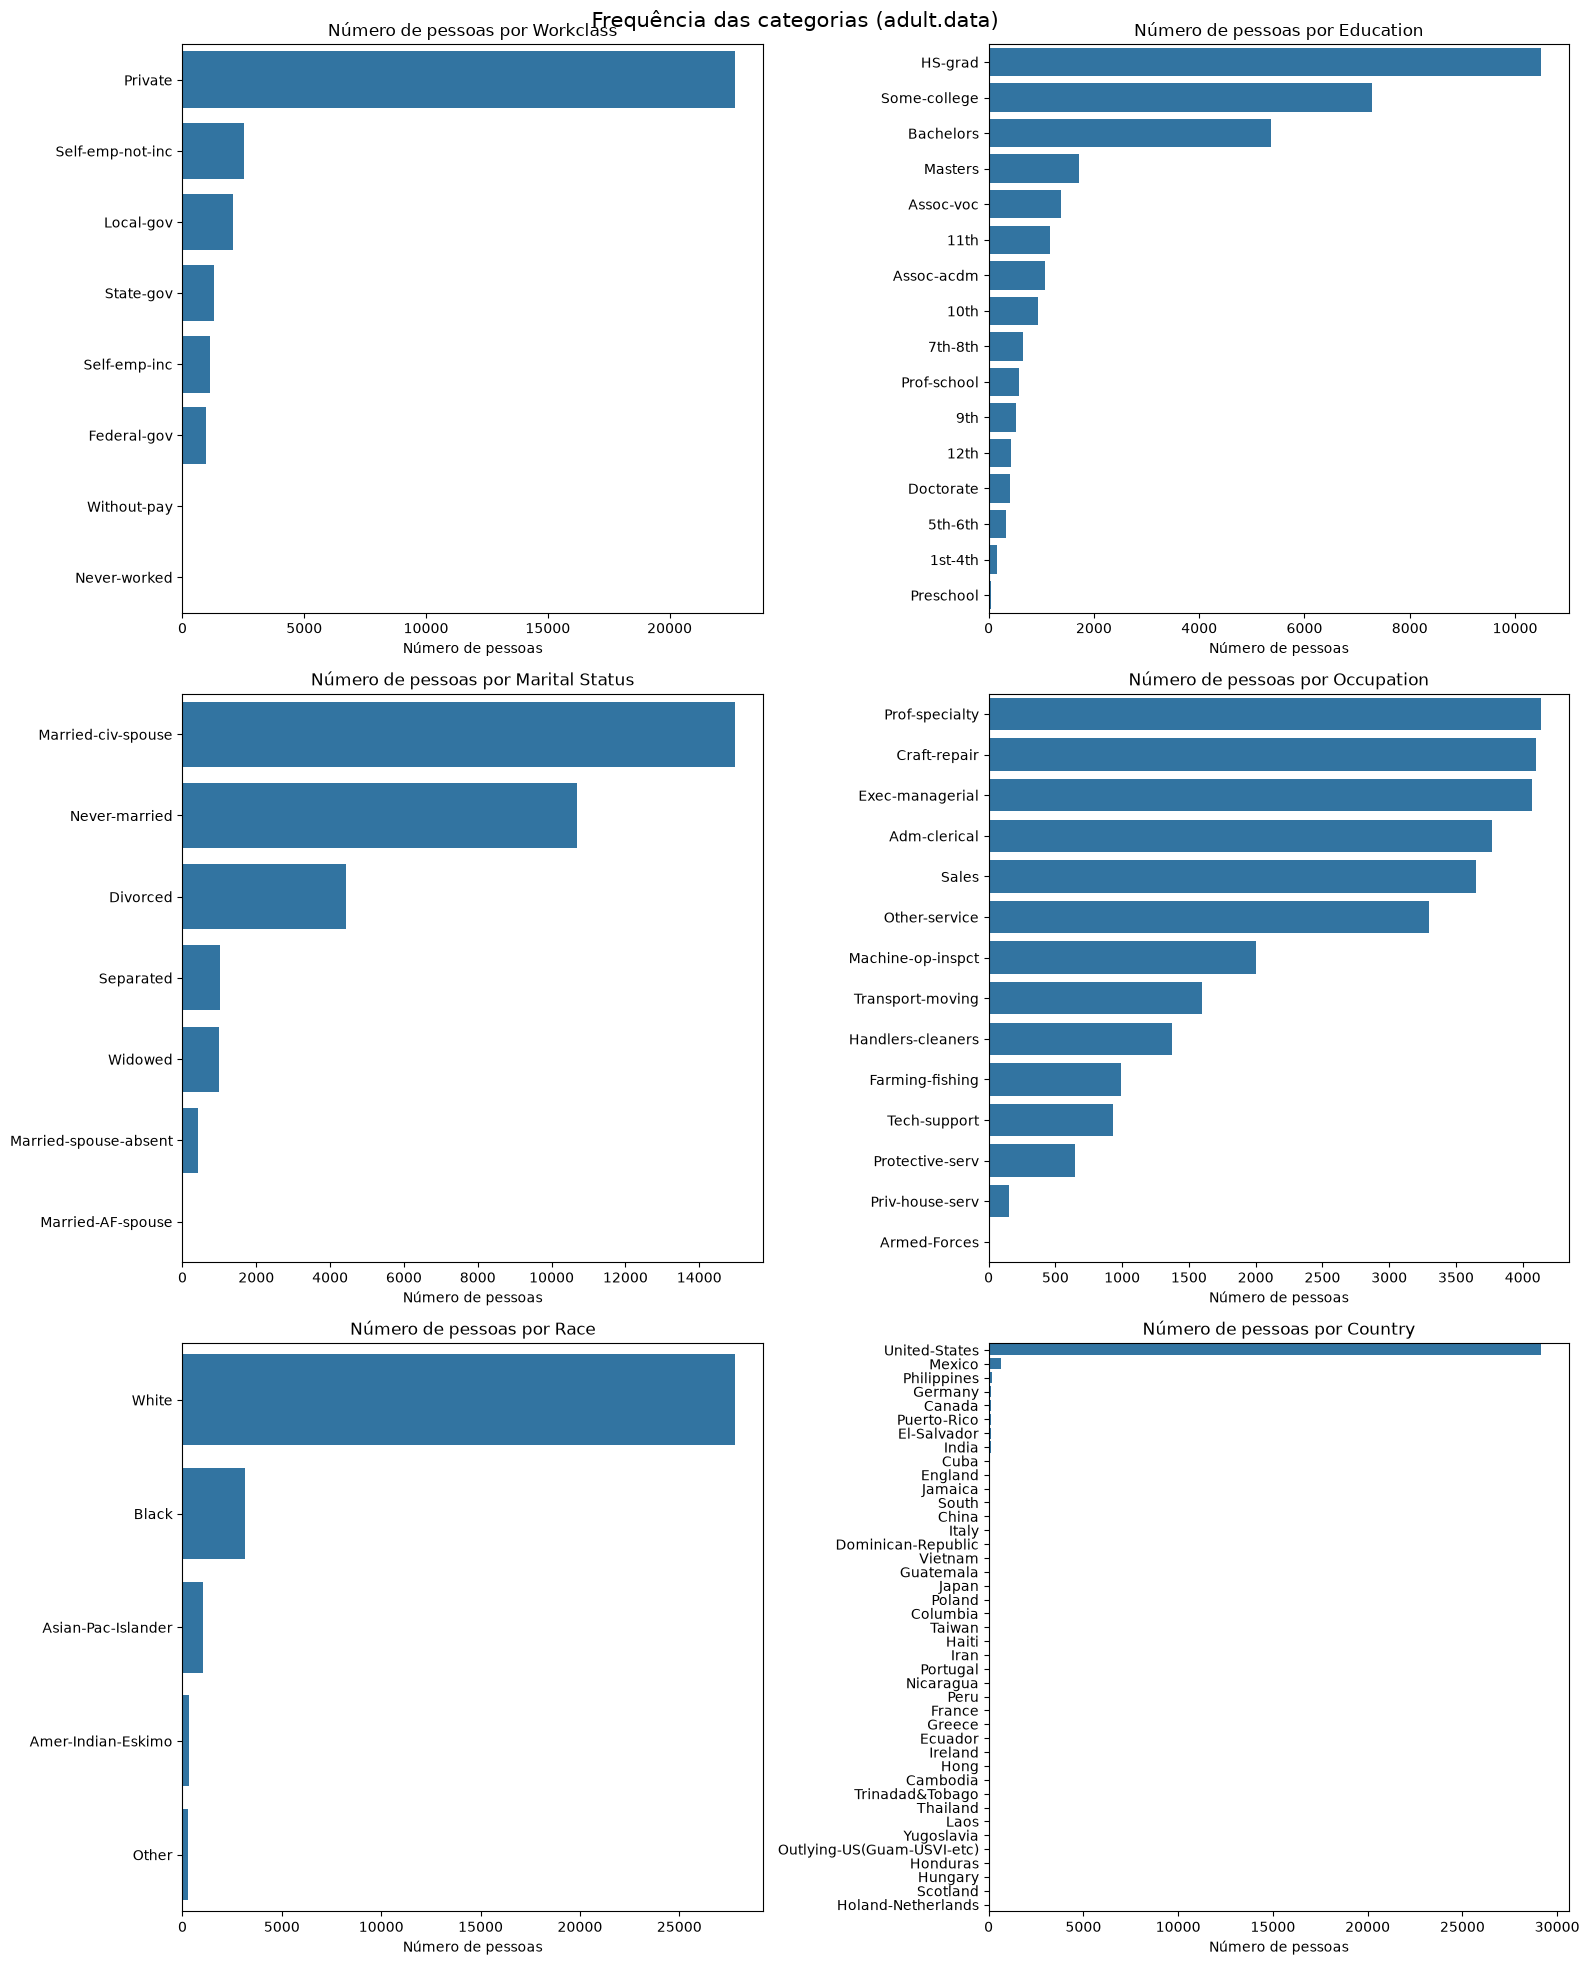

In [28]:
cols_freq = ["Workclass", "Education", "Marital Status", "Occupation", "Race", "Country"]

fig, axes = plt.subplots(3, 2, figsize=(16, 20))
for ax, coluna in zip(axes.ravel(), cols_freq):
    contagem = adult_data[coluna].value_counts()
    sns.barplot(x=contagem.values, y=contagem.index, ax=ax)
    ax.set_title(f"Número de pessoas por {coluna}")
    ax.set_xlabel("Número de pessoas")
    ax.set_ylabel("")
fig.suptitle("Frequência das categorias (adult.data)", fontsize=15)
plt.tight_layout()
plt.show()

In [29]:
print((adult_data["Country"].value_counts(normalize=True).head(3) * 100).round(1))
print()
print((adult_data["Race"].value_counts(normalize=True) * 100).round(1))

Country
United-States    91.2
Mexico            2.0
Philippines       0.6
Name: proportion, dtype: float64

Race
White                 85.4
Black                  9.6
Asian-Pac-Islander     3.2
Amer-Indian-Eskimo     1.0
Other                  0.8
Name: proportion, dtype: float64


**Conclusão.** As categorias têm tamanhos muito desiguais. `Country` é dominada por `United-States` (91,2%), seguida de `Mexico` (2,0%) e `Philippines` (0,6%), e as cerca de 38 demais categorias somam pouco; isso justifica testar, em uma ablação, reduzir `Country` a US/não-US. `Race` é majoritariamente `White` (85,4%), e as taxas de renda alta de `Amer-Indian-Eskimo` (1,0%) e `Other` (0,8%) vêm de grupos pequenos (311 e 271 pessoas), por isso são menos confiáveis. Em `Workclass`, `Private` reúne a maioria das pessoas, e `Never-worked` e `Without-pay` têm 7 e 14 registros, o que explica as taxas de 0% vistas antes. Em `Marital Status`, `Married-civ-spouse` e `Never-married` concentram a maior parte, e `Married-AF-spouse` quase não aparece. `Education` se concentra em `HS-grad`, `Some-college` e `Bachelors`, com os níveis mais baixos (`Preschool`, `1st-4th`) muito raros. `Occupation` é a mais equilibrada, com `Armed-Forces` (9 registros) como exceção. Como o one-hot cria uma coluna por categoria, essas categorias raras viram colunas quase sempre zero e pouco informam ao kNN.

### 2.5 Correlação entre variáveis numéricas

Verificamos se há variáveis numéricas muito correlacionadas entre si, o que indicaria redundância.

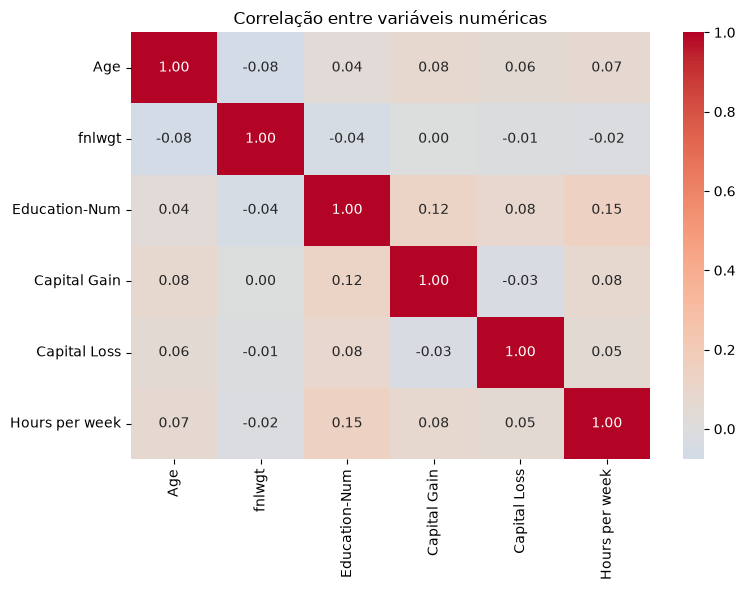

        Education  Education-Num
224     Preschool              1
160       1st-4th              2
56        5th-6th              3
15        7th-8th              4
6             9th              5
77           10th              6
3            11th              7
415          12th              8
2         HS-grad              9
10   Some-college             10
14      Assoc-voc             11
13     Assoc-acdm             12
0       Bachelors             13
5         Masters             14
52    Prof-school             15
20      Doctorate             16


In [30]:
fig, ax = plt.subplots(figsize=(8, 6))
corr = adult_data[colunas_numericas].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlação entre variáveis numéricas")
plt.tight_layout()
plt.show()

print(adult_data[["Education", "Education-Num"]].drop_duplicates().sort_values("Education-Num"))

**Conclusão.** As correlações entre as variáveis numéricas são fracas: o maior valor absoluto é 0,15 (`Education-Num` com `Hours per week`), seguido de 0,12 (`Education-Num` com `Capital Gain`). Isso sugere pouca redundância linear entre essas variáveis numéricas, mas não permite concluir que não haja redundância com variáveis categóricas. De fato, `Education` e `Education-Num` têm correspondência exata de um para um nos 16 níveis observados, de `Preschool` (1) a `Doctorate` (16), representando a mesma informação por codificações distintas. Mantê-las pode aumentar o peso relativo da escolaridade nas distâncias do kNN: uma representação é numérica padronizada e a outra é codificada em colunas one-hot. No modelo base mantivemos ambas por simplicidade, mas testaremos remover `Education` na ablação.

## Modelo base: kNN com pré-processamento em pipeline

Nesta seção construímos o modelo de referência: descartamos as linhas incompletas, separamos treino e holdout, padronizamos as numéricas, aplicamos one-hot nas categóricas e escolhemos k por validação cruzada. Os resultados servem de base de comparação para as ablações da seção 3.

**Tratamento de ausentes (versão base).** Para o modelo base, as linhas com qualquer valor ausente são descartadas, tanto no treino quanto no holdout. É uma escolha simples e aceitável, porque os ausentes ficam em só três colunas categóricas e afetam cerca de 7% das linhas (seção 2.2), restando 30.162 linhas de treino e 15.060 de holdout. Para o Kaggle isso não é possível, e lá usamos imputação pela moda. O `adult.test` serve de **holdout**: só é usado para avaliar modelos já escolhidos (o base e o final), nunca para escolher parâmetros.

In [31]:
adult_clean = adult_data.dropna()
test_clean = adult_test.dropna()

In [32]:
adult_clean.shape

(30162, 15)

In [33]:
test_clean.shape

(15060, 15)

In [34]:
adult_data_treinamento = adult_clean.drop(columns = "Target")
adult_data_resposta = adult_clean["Target"]
adult_test_avaliação = test_clean.drop(columns = "Target")
adult_test_resposta= test_clean["Target"]


In [35]:
adult_data_treinamento.shape

(30162, 14)

In [36]:
adult_data_resposta.shape

(30162,)

In [37]:
adult_test_avaliação.shape

(15060, 14)

In [38]:
adult_test_resposta.shape

(15060,)

In [39]:
adult_data_treinamento.dtypes

Age               int64
Workclass           str
fnlwgt            int64
Education           str
Education-Num     int64
Marital Status      str
Occupation          str
Relationship        str
Race                str
Sex                 str
Capital Gain      int64
Capital Loss      int64
Hours per week    int64
Country             str
dtype: object

**Pré-processamento.** O kNN compara pessoas por distância, então a escala das variáveis importa e as categorias precisam virar números. Por isso: (i) as variáveis numéricas são padronizadas (`StandardScaler`), para que `fnlwgt`, na casa das centenas de milhares, não domine `Age`, na casa das dezenas; (ii) as categóricas recebem *one-hot* (`OneHotEncoder`). Descartamos o `LabelEncoder` porque ele atribui números inteiros às categorias e criaria uma ordem falsa (por exemplo, `Sales` "maior" que `Craft-repair`), que distorceria as distâncias. `handle_unknown="ignore"` evita erro se aparecer uma categoria inédita. Tudo é montado em um `Pipeline`, de modo que a padronização e o one-hot são ajustados só com os dados de treino de cada dobra da validação cruzada, sem vazamento de informação.

In [40]:
preprocessador = ColumnTransformer([("final_numbers", StandardScaler(), colunas_numericas), ("final_categorics", OneHotEncoder(handle_unknown="ignore"), colunas_categoricas)])

In [41]:
Xadult = preprocessador.fit_transform(adult_data_treinamento)
Xadult.shape

(30162, 104)

In [42]:
model = [("prep", preprocessador), ("knn", KNeighborsClassifier(n_neighbors= 5))]
sleep = Pipeline(model)

In [43]:
resultado_final = cross_val_score(sleep, adult_data_treinamento, adult_data_resposta, cv=5).mean()
print(resultado_final)

0.8283273835197308


**Escolha de k.** O número de vizinhos é escolhido por validação cruzada de 5 dobras (`GridSearchCV`), usando apenas o treino. A validação cruzada de classificadores é estratificada por padrão, o que mantém a proporção entre as classes em cada dobra (importante com 76% de `<=50K`). Os candidatos são, em sua maioria, ímpares, para evitar empates na votação entre duas classes; 40 e 42 foram incluídos só para conferir a vizinhança do valor ótimo. A lista é concentrada em valores grandes porque uma primeira exploração com k=5 já mostrou acurácia de 0,8283, abaixo dos resultados com k maior; a curva de k mais adiante confirma isso numa faixa ampla.

In [44]:
candidatos = [21, 25, 31, 35, 39, 40, 41, 42, 45, 51]
parametros = {"knn__n_neighbors": candidatos}
busca = GridSearchCV(sleep, parametros, cv=5, n_jobs = 2, verbose =2)

In [45]:
busca.fit(adult_data_treinamento, adult_data_resposta)

Fitting 5 folds for each of 10 candidates, totalling 50 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'knn__n_neighbors': [21, 25, ...]}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",2
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection str

In [46]:
print(busca.best_params_)
print(busca.best_score_)

{'knn__n_neighbors': 41}
0.839334626618145


In [47]:
previsao = busca.predict(adult_test_avaliação)

In [48]:
acuracia = accuracy_score(adult_test_resposta, previsao)
print(acuracia)

0.8389774236387783


In [49]:
error = (1 - acuracia)
print(error)

0.16102257636122175


## Resultado do modelo base

**Configuração**
- Classificador: kNN, com pré-processamento em pipeline (padronização das variáveis numéricas e one-hot das categóricas).
- Tratamento de ausentes: linhas com valores faltantes foram descartadas, tanto no treino (30.162 linhas restantes) quanto no holdout (15.060 linhas restantes). Para o modelo da submissão do Kaggle isso não é possível, e lá usamos imputação pela moda (seção 4).
- Escolha de `k`: validação cruzada de 5 dobras, usando apenas o treino, com candidatos predominantemente ímpares para reduzir a possibilidade de empate na votação.

**Resultados**
- Melhor `k`: **41**, com acurácia média de validação de **0,8393**.
- Acurácia no holdout: **0,8390**.
- Erro empírico no holdout: **0,1610 (16,1%)**.

**Interpretação**
A acurácia no holdout ficou muito próxima da média da validação cruzada (diferença de cerca de 0,0003), o que é uma evidência favorável de consistência do desempenho nessas avaliações. Essa proximidade, contudo, não garante generalização para outras amostras ou distribuições. Com 15.060 exemplos no holdout, o erro-padrão binomial aproximado é de cerca de 0,3 ponto percentual. Um intervalo aproximado de 95% para o erro é de 15,5% a 16,7%, sob as hipóteses binomiais; esse intervalo não incorpora toda a incerteza decorrente da seleção e do treinamento do modelo. Portanto, diferenças pequenas devem ser interpretadas com cautela, não classificadas automaticamente como estatisticamente inconclusivas apenas por um limite fixo.

**Observação sobre a escolha de `k`**
Duas buscas com listas diferentes de candidatos selecionaram `k=41`. Como ambas usam os mesmos dados de treino e o mesmo esquema de validação cruzada, não são buscas estatisticamente independentes. A curva ampla mostra desempenho relativamente próximo para valores de `k` entre 21 e 71, indicando que a escolha é pouco sensível à lista de candidatos considerada nessa validação.

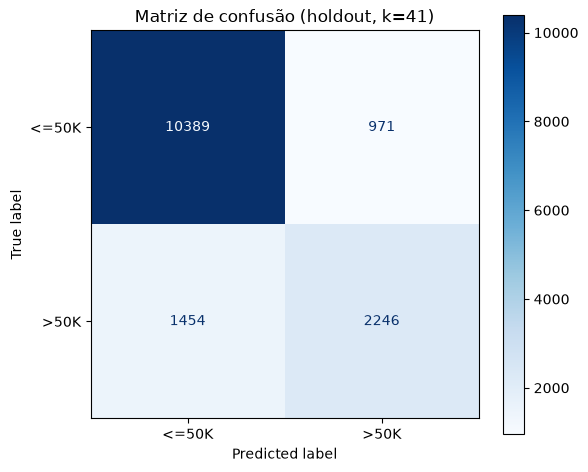

In [50]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(adult_test_resposta, previsao, ax=ax, cmap="Blues", values_format="d")
ax.set_title("Matriz de confusão (holdout, k=41)")
plt.tight_layout()
plt.show()

In [51]:
print(classification_report(adult_test_resposta, previsao, digits=3))

              precision    recall  f1-score   support

       <=50K      0.877     0.915     0.895     11360
        >50K      0.698     0.607     0.649      3700

    accuracy                          0.839     15060
   macro avg      0.788     0.761     0.772     15060
weighted avg      0.833     0.839     0.835     15060



**Conclusão.** A matriz de confusão mostra que o desempenho é desigual entre as classes. O modelo acerta 91,5% das pessoas que ganham `<=50K` (revocação de 0,915), mas só 60,7% das que ganham `>50K` (revocação de 0,607): das 3700 pessoas de renda alta no holdout, 1454 foram classificadas como `<=50K`. A precisão da classe `>50K` é 69,8%, ou seja, quando o modelo prevê renda alta, acerta cerca de 7 em cada 10 vezes, e o F1 dessa classe é 0,649, contra 0,895 da classe majoritária. Isso confirma o alerta da seção 2.1: a acurácia de 83,9% é puxada pela classe majoritária, e o erro se concentra nos falsos negativos da classe minoritária. O kNN vota por maioria entre os vizinhos, então em regiões onde as classes se misturam a maioria `<=50K` tende a vencer. Por isso, nas ablações, vamos olhar também a revocação de `>50K`, e não só a acurácia.

### Curva de k

Para ver como o erro varia com o número de vizinhos, repetimos a validação cruzada em uma faixa larga de valores de k, de 1 a 101.

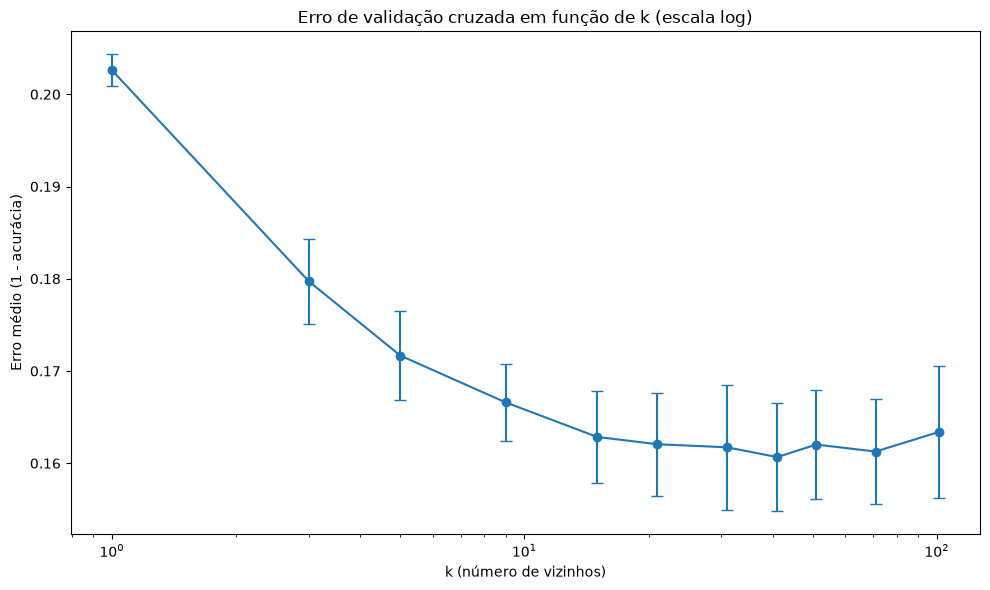

    param_knn__n_neighbors  mean_test_score  std_test_score
0                        1           0.7974          0.0017
1                        3           0.8203          0.0046
2                        5           0.8283          0.0048
3                        9           0.8334          0.0042
4                       15           0.8371          0.0050
5                       21           0.8379          0.0056
6                       31           0.8383          0.0068
7                       41           0.8393          0.0059
8                       51           0.8380          0.0059
9                       71           0.8387          0.0057
10                     101           0.8366          0.0072


In [52]:
ks = [1, 3, 5, 9, 15, 21, 31, 41, 51, 71, 101]
busca_larga = GridSearchCV(sleep, {"knn__n_neighbors": ks}, cv=5, n_jobs=2)
busca_larga.fit(adult_data_treinamento, adult_data_resposta)

res = pd.DataFrame(busca_larga.cv_results_).sort_values("param_knn__n_neighbors")
fig, ax = plt.subplots(figsize=(10, 6))
ax.errorbar(res["param_knn__n_neighbors"], 1 - res["mean_test_score"],
            yerr=res["std_test_score"], marker="o", capsize=4)
ax.set_xscale("log")
ax.set_title("Erro de validação cruzada em função de k (escala log)")
ax.set_xlabel("k (número de vizinhos)")
ax.set_ylabel("Erro médio (1 - acurácia)")
plt.tight_layout()
plt.show()

print(res[["param_knn__n_neighbors", "mean_test_score", "std_test_score"]].round(4))

**Conclusão.** O erro diminui rapidamente quando aumentamos valores muito pequenos de `k`: para `k=1`, é de aproximadamente 20,3%; para `k=5`, de 17,2%; e, para `k=15`, de 16,3%.

A partir de `k≈21`, a curva apresenta pouca variação, com erros entre aproximadamente 16,1% e 16,3% até `k=101`. O menor erro médio observado ocorre em `k=41`, com aproximadamente 16,07%. Entretanto, os resultados dos valores de `k=21`, `31`, `41`, `51` e `71` são próximos, e as diferenças observadas são pequenas em relação à dispersão entre as dobras da validação cruzada.

Esses resultados sugerem que o desempenho do modelo é relativamente pouco sensível à escolha de `k` nessa faixa de valores. Portanto, `k=41` é uma escolha razoável entre os candidatos avaliados, embora os resultados não demonstrem equivalência estatística formal entre essas configurações. O leve aumento do erro em `k=101` também indica que aumentar o número de vizinhos não garante melhorias contínuas no desempenho.

## 3. Ablações

Cada ablação remove ou altera um componente do modelo e compara a validação cruzada de 5 dobras, com `k=41` fixo, à referência. O limite de 0,3 ponto percentual é usado como referência exploratória para chamar atenção a diferenças pequenas, e não como critério formal de significância estatística. A dispersão entre dobras e a correlação entre os resultados dos modelos precisam ser consideradas; uma comparação formal exigiria um procedimento apropriado para estimar a incerteza das diferenças. O holdout fica reservado para a avaliação do modelo final.

In [53]:
from sklearn.metrics import make_scorer, recall_score
from sklearn.model_selection import cross_validate

pontuacoes = {"acuracia": "accuracy",
              "recall_maior": make_scorer(recall_score, pos_label=">50K")}

def avaliar(nome, preproc, X, k=41):
    modelo = Pipeline([("prep", preproc), ("knn", KNeighborsClassifier(n_neighbors=k))])
    r = cross_validate(modelo, X, adult_data_resposta, cv=5, scoring=pontuacoes, n_jobs=2)
    print(f"{nome}: acurácia {r['test_acuracia'].mean():.4f} | recall >50K {r['test_recall_maior'].mean():.4f}")

# referência: o modelo base, para comparar com as variações
avaliar("Base (k=41)", preprocessador, adult_data_treinamento)

Base (k=41): acurácia 0.8393 | recall >50K 0.6071


### 3.1 Remover `Education`

Na seção 2.5 vimos que `Education` repete a informação de `Education-Num` (correspondência exata, 16 níveis). Aqui removemos `Education` e mantemos só `Education-Num`.

In [54]:
cat_sem_education = [c for c in colunas_categoricas if c != "Education"]
prep_sem_education = ColumnTransformer([
    ("num", StandardScaler(), colunas_numericas),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_sem_education),
])
avaliar("Sem Education", prep_sem_education, adult_data_treinamento)

Sem Education: acurácia 0.8414 | recall >50K 0.6055


**Conclusão.** Remover `Education` elevou a acurácia de 0,8393 para 0,8414 (+0,21 ponto percentual) e deixou o recall de `>50K` próximo do valor base (0,6055 contra 0,6071). Como a diferença de acurácia é pequena, ela deve ser interpretada com cautela; o limite de 0,3 ponto percentual adotado neste trabalho é exploratório, não um teste estatístico. O resultado é coerente com a redundância entre `Education` e `Education-Num`: mantê-las pode aumentar o peso relativo da escolaridade na distância do kNN, por meio de uma variável numérica padronizada e de colunas one-hot. O modelo sem `Education` é mais simples e apresentou desempenho ligeiramente superior nesta validação, por isso é um candidato razoável ao modelo final.

### 3.2 Remover `fnlwgt`

Na seção 2.3 vimos que `fnlwgt` tem medianas quase idênticas nas duas classes. Aqui removemos essa variável.

In [55]:
num_sem_fnlwgt = [c for c in colunas_numericas if c != "fnlwgt"]
prep_sem_fnlwgt = ColumnTransformer([
    ("num", StandardScaler(), num_sem_fnlwgt),
    ("cat", OneHotEncoder(handle_unknown="ignore"), colunas_categoricas),
])
avaliar("Sem fnlwgt", prep_sem_fnlwgt, adult_data_treinamento)

Sem fnlwgt: acurácia 0.8406 | recall >50K 0.6123


**Conclusão.** Remover `fnlwgt` elevou a acurácia de 0,8393 para 0,8406 (+0,13 ponto percentual) e o recall de `>50K` de 0,6071 para 0,6123. As diferenças são pequenas e devem ser interpretadas com cautela; o limite de 0,3 ponto percentual é uma referência exploratória, não um teste formal. As medianas quase idênticas entre as classes sugerem capacidade discriminativa limitada nessa comparação, e a ablação indica que remover a variável não prejudicou o desempenho observado. Isso não demonstra que `fnlwgt` não contenha informação preditiva em geral, mas sustenta sua remoção nesta configuração por simplificar o modelo sem perda observada.

### 3.3 Log em `Capital Gain` e `Capital Loss`

Na seção 2.3.1 vimos que essas duas variáveis são extremamente assimétricas (assimetria 11,95 e 4,59), com mais de 90% de zeros. Aplicamos `log(1 + x)` antes da padronização, para reduzir o peso dos valores extremos nas distâncias.

In [56]:
num_normais = ["Age", "fnlwgt", "Education-Num", "Hours per week"]
prep_log = ColumnTransformer([
    ("num", StandardScaler(), num_normais),
    ("log", Pipeline([("log", FunctionTransformer(np.log1p)),
                      ("escala", StandardScaler())]), ["Capital Gain", "Capital Loss"]),
    ("cat", OneHotEncoder(handle_unknown="ignore"), colunas_categoricas),
])
avaliar("Log em Capital Gain/Loss", prep_log, adult_data_treinamento)

Log em Capital Gain/Loss: acurácia 0.8392 | recall >50K 0.6411


**Conclusão.** A transformação `log(1 + x)` em `Capital Gain` e `Capital Loss` manteve a acurácia praticamente inalterada (0,8392 contra 0,8393), mas elevou o recall de `>50K` de 0,6071 para 0,6411, um ganho observado de 3,4 pontos percentuais. Esse ganho é relevante do ponto de vista prático e justifica investigar a transformação. Contudo, o notebook não apresenta a variabilidade do recall entre as dobras nem um teste formal de comparação; portanto, não é possível concluir, a partir do desvio-padrão da acurácia, que o ganho de recall seja estatisticamente maior que o ruído. A transformação pode reduzir a influência de valores extremos nas distâncias, mas a análise não demonstra que esses valores dominavam as distâncias individuais. Como o ganho de capital é mais frequente na classe `>50K` (21,4% contra 4,2%), é plausível que a transformação ajude a identificar melhor essa classe. A acurácia quase constante junto ao recall maior indica uma mudança na distribuição dos erros entre as classes.

### 3.4 `Country` reduzido a US / não-US

Na seção 2.4.1 vimos que 91,2% das pessoas são `United-States` e que as outras cerca de 38 categorias são muito pequenas. Aqui agrupamos todos os países que não são os EUA em uma única categoria.

In [57]:
X_pais = adult_data_treinamento.copy()
X_pais["Country"] = np.where(X_pais["Country"] == "United-States", "US", "Outro")
avaliar("Country US/Outro", preprocessador, X_pais)

Country US/Outro: acurácia 0.8397 | recall >50K 0.6051


**Conclusão.** Agrupar `Country` em US e não-US manteve desempenho semelhante: acurácia de 0,8397 contra 0,8393 (+0,04 ponto percentual) e recall de `>50K` de 0,6051 contra 0,6071 (-0,20 ponto). As diferenças são pequenas e, nesta análise exploratória, não sustentam uma conclusão forte de ganho ou perda. Como 91,2% das pessoas são dos Estados Unidos e as demais categorias têm frequências menores, agrupá-las reduz a dimensionalidade da representação one-hot. A simplificação é possível, mas não mostrou benefício claro nas métricas observadas.

### 3.5 `Marital Status` e `Relationship`

Na seção 2.4 vimos que as duas variáveis carregam praticamente a mesma informação (casados concentram renda alta nas duas). Testamos manter só uma de cada vez.

In [58]:
cat_sem_relationship = [c for c in colunas_categoricas if c != "Relationship"]
prep_sem_rel = ColumnTransformer([
    ("num", StandardScaler(), colunas_numericas),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_sem_relationship),
])
avaliar("Sem Relationship", prep_sem_rel, adult_data_treinamento)

cat_sem_marital = [c for c in colunas_categoricas if c != "Marital Status"]
prep_sem_mar = ColumnTransformer([
    ("num", StandardScaler(), colunas_numericas),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_sem_marital),
])
avaliar("Sem Marital Status", prep_sem_mar, adult_data_treinamento)

Sem Relationship: acurácia 0.8362 | recall >50K 0.5991
Sem Marital Status: acurácia 0.8365 | recall >50K 0.5898


**Conclusão.** Remover `Relationship` reduziu a acurácia de 0,8393 para 0,8362, uma queda de 0,31 ponto percentual, e resultou em recall de 0,5991 para a classe `>50K`. Remover `Marital Status` levou a uma acurácia de 0,8365, uma queda de 0,28 ponto percentual, e a um recall de 0,5898 para a mesma classe.

As métricas observadas pioraram nas duas ablações, especialmente o recall da classe `>50K`. Embora não tenha sido realizado um teste formal de significância, os resultados sugerem que a remoção de qualquer uma dessas variáveis prejudica o desempenho desta configuração do modelo.

As variáveis podem conter informações parcialmente sobrepostas, mas representam aspectos distintos: `Marital Status` registra o estado civil, enquanto `Relationship` descreve a relação do indivíduo com a pessoa de referência no domicílio. Os resultados são compatíveis com a hipótese de que ambas fornecem informações úteis para a classificação. Por esse motivo, mantemos as duas no modelo final.

### 3.6 Combinação das ablações

Juntamos as mudanças que não pioraram o modelo: sem `Education`, sem `fnlwgt` e log em `Capital Gain` e `Capital Loss`, mantendo `Marital Status` e `Relationship`. A variante B soma também o agrupamento de `Country` em US/não-US.


In [59]:
num_final = ["Age", "Education-Num", "Hours per week"]
cat_final = [c for c in colunas_categoricas if c != "Education"]

prep_final = ColumnTransformer([
    ("num", StandardScaler(), num_final),
    ("log", Pipeline([("log", FunctionTransformer(np.log1p)),
                      ("escala", StandardScaler())]), ["Capital Gain", "Capital Loss"]),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_final),
])

avaliar("Combinado A (sem Education/fnlwgt + log)", prep_final, adult_data_treinamento)
avaliar("Combinado B (A + Country US/Outro)", prep_final, X_pais)

Combinado A (sem Education/fnlwgt + log): acurácia 0.8430 | recall >50K 0.6452
Combinado B (A + Country US/Outro): acurácia 0.8433 | recall >50K 0.6437


**Conclusão.** A combinação das mudanças (sem `Education`, sem `fnlwgt` e com log em `Capital Gain` e `Capital Loss`) elevou a acurácia de 0,8393 para 0,8430 (+0,37 ponto percentual) e o recall de `>50K` de 0,6071 para 0,6452 (+3,8 pontos). O ganho observado no recall vem principalmente da transformação logarítmica, que sozinha já levou o recall a 0,6411 (seção 3.3); contudo, não foi realizado um teste formal para quantificar a incerteza dessa diferença. Remover `Education` e `fnlwgt` simplifica o modelo e apresentou pequeno ganho de acurácia. Acrescentar o agrupamento de `Country` (variante B) não melhorou claramente o resultado (acurácia 0,8433 e recall 0,6437), então mantivemos a variante A. O modelo final usa `Age`, `Education-Num` e `Hours per week` padronizadas; `Capital Gain` e `Capital Loss` transformadas com `log(1 + x)` e depois padronizadas; e one-hot de `Workclass`, `Marital Status`, `Occupation`, `Relationship`, `Race`, `Sex` e `Country`. Mantemos `Marital Status` e `Relationship`, pois removê-las piorou as métricas observadas (seção 3.5).

### 3.7 Modelo final: k e holdout

Com o pré-processamento final, refazemos a busca de k por validação cruzada (apenas no treino) e avaliamos uma única vez no holdout.


In [60]:
modelo_final = Pipeline([("prep", prep_final), ("knn", KNeighborsClassifier())])
busca_final = GridSearchCV(modelo_final,
                           {"knn__n_neighbors": [15, 21, 31, 41, 51, 71]},
                           cv=5, n_jobs=2)
busca_final.fit(adult_data_treinamento, adult_data_resposta)
print(busca_final.best_params_, round(busca_final.best_score_, 4))

previsao_final = busca_final.predict(adult_test_avaliação)
print("Acurácia no holdout:", round(accuracy_score(adult_test_resposta, previsao_final), 4))
print(classification_report(adult_test_resposta, previsao_final, digits=3))

{'knn__n_neighbors': 51} 0.8443
Acurácia no holdout: 0.8446
              precision    recall  f1-score   support

       <=50K      0.887     0.909     0.898     11360
        >50K      0.699     0.646     0.671      3700

    accuracy                          0.845     15060
   macro avg      0.793     0.778     0.785     15060
weighted avg      0.841     0.845     0.842     15060



**Conclusão.** Com o pré-processamento final, a busca de `k` escolheu `k=51`, com acurácia média de validação de 0,8443. No holdout, avaliado uma única vez, a acurácia foi 0,8446 (erro de 15,5%), contra 0,8390 (erro de 16,1%) do modelo base: uma melhora observada de 0,56 ponto percentual. A proximidade entre validação e holdout é evidência favorável de consistência nas avaliações realizadas, mas não garante generalização para outras amostras ou distribuições. O recall de `>50K` subiu de 0,607 para 0,646 e o F1 dessa classe de 0,649 para 0,671, com precisão de 0,699 no modelo final. O recall de `<=50K` caiu de 0,915 para 0,909, uma troca compatível com identificar mais pessoas de renda alta ao custo de alguns falsos positivos. A mudança de `k=41` para `k=51` contribui pouco: o mesmo pré-processamento com `k=41` teve acurácia de validação de 0,8430 (seção 3.6), e `k=51` acrescentou 0,13 ponto percentual. Essa diferença é pequena e não foi submetida a teste formal; os resultados sugerem que o ganho observado em relação ao modelo base vem principalmente do pré-processamento, sobretudo do log em `Capital Gain` e `Capital Loss`.

## 4. Modelo da submissão para o Kaggle

O `test_data.csv` do Kaggle tem valores ausentes, e todas as linhas precisam receber uma previsão. Por isso, o pipeline da submissão usa o **pré-processamento e o valor de `k` selecionados para o modelo final** (sem `Education` e `fnlwgt`, log em `Capital Gain` e `Capital Loss`, `k=51`), mas não é literalmente o mesmo estimador já avaliado no holdout: ele é reajustado com os 32.561 registros de `adult.data`, sem descartar linhas, e as variáveis categóricas passam por imputação pela moda (`SimpleImputer`) dentro do pipeline. Não há holdout próprio para esse modelo de submissão. O desempenho de 0,8446 é a acurácia do modelo final na avaliação anterior, não uma medição do desempenho no conjunto oculto do Kaggle; o score da plataforma deve ser registrado apenas quando estiver disponível.

In [61]:
identificador = kaggle_data["Id"]
Xkaggle_data = kaggle_data.drop(columns="Id")

In [62]:
Xkaggle_data.columns = adult_data_treinamento.columns

In [63]:
print( list(Xkaggle_data.columns) == list(adult_data_treinamento.columns))

True


In [64]:
preprocessador_imp = ColumnTransformer([
    ("num", StandardScaler(), num_final),
    ("log", Pipeline([("log", FunctionTransformer(np.log1p)),
                      ("escala", StandardScaler())]), ["Capital Gain", "Capital Loss"]),
    ("cat", Pipeline([("imputador", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_final),
])  

In [65]:
pipeline_imp = Pipeline([
    ("prep", preprocessador_imp),
    ("knn", KNeighborsClassifier(n_neighbors=51)),
])

In [66]:
# dados completos, sem descartar nenhuma linha
X_completo = adult_data.drop(columns="Target")
y_completo = adult_data["Target"]
print(X_completo.shape, y_completo.shape)   # esperado: (32561, 14) (32561,)


(32561, 14) (32561,)


In [67]:
# treina e prevê o teste do Kaggle
pipeline_imp.fit(X_completo, y_completo)
previsao_kaggle = pipeline_imp.predict(Xkaggle_data)
print(len(previsao_kaggle))                 # esperado: 16280

16280


In [68]:
# arquivo de entrega
submission = pd.DataFrame({"Id": identificador, "income": previsao_kaggle})
submission.to_csv("submission.csv", index=False)
print(submission.shape)                     # esperado: (16280, 2)
print(submission["income"].value_counts(normalize=True))

(16280, 2)
income
<=50K    0.784889
>50K     0.215111
Name: proportion, dtype: float64


## Conclusão geral

Os experimentos mostram que as escolhas de pré-processamento e de representação das variáveis influenciam o desempenho do classificador kNN. O modelo base, com `k=41`, obteve acurácia média de 0,8393 na validação cruzada e acurácia de 0,8390 no holdout. Após as ablações e a seleção da configuração final, o modelo com `k=51` alcançou acurácia média de 0,8443 na validação cruzada e 0,8446 no holdout.

No modelo final, o recall da classe `>50K` foi de aproximadamente 0,646, indicando que o classificador identificou cerca de 64,6% dos indivíduos dessa classe no holdout. Esse resultado complementa a acurácia, pois permite avaliar o desempenho especificamente na classe de maior renda, que representa a parcela minoritária do conjunto de dados.

A comparação entre o modelo base e o final indica uma melhora nas métricas observadas. No entanto, como não foi realizado um teste formal de significância, não podemos afirmar que toda a diferença decorre de uma melhora estatisticamente significativa. Os resultados devem ser interpretados como evidência empírica favorável à configuração final dentro dos experimentos realizados.

| Configuração | Melhor k | Acurácia média (CV) | Acurácia no holdout | Recall de `>50K` | Score no Kaggle |
|---|---:|---:|---:|---:|---:|
| Modelo base | 41 | 0,8393 | 0,8390 | 0,607 | 0,84275 |
| Modelo final | 51 | 0,8443 | 0,8446 | 0,646 | 0,84815 |

O score do modelo base (0,84275) vem da primeira submissão ao Kaggle, feita com `k=41` e as variáveis numéricas padronizadas. O score do modelo final (0,84815) vem da submissão feita com a configuração das ablações (`k=51`, log em Capital Gain/Loss, sem Education). Os dois scores são calculados pelo Kaggle sobre o conjunto de teste da competição e, por isso, não são diretamente comparáveis com a acurácia no holdout.

Por fim, a versão submetida ao Kaggle é treinada novamente com todos os registros disponíveis em `adult.data` e utiliza imputação para tratar os valores ausentes. Portanto, ela segue a configuração de pré-processamento selecionada, mas não corresponde exatamente ao mesmo ajuste de modelo avaliado no holdout.